<br><br>

# COMSATS University Islamabad
## Department of Computer Science
### Lab Assignment 2 - ANN & DL

**Name:** Khair ul wara Hussain
**Registration No:** FA23-BAI-022
**Class:** BSAI-7
**Subject:** ANN & DL
**Submission Deadline:** 19-10-2026

# Task 1 - ANN Training and Hyperparameter Investigation

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

### 1. Dataset preparation

In [2]:
iris = load_iris()
X = iris.data
y = iris.target

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("train:", X_train.shape, "val:", X_val.shape, "test:", X_test.shape)

train: (90, 4) val: (30, 4) test: (30, 4)


In [3]:
def build_model(act='relu', init='he_normal', units=16, l1=0.0, l2=0.0, drop=0.0, lr=0.01):
    reg = None
    if l1 > 0 or l2 > 0:
        reg = regularizers.l1_l2(l1=l1, l2=l2)
    model = keras.Sequential()
    model.add(layers.Input(shape=(4,)))
    model.add(layers.Dense(units, activation=act, kernel_initializer=init, kernel_regularizer=reg))
    if drop > 0:
        model.add(layers.Dropout(drop))
    model.add(layers.Dense(units, activation=act, kernel_initializer=init, kernel_regularizer=reg))
    if drop > 0:
        model.add(layers.Dropout(drop))
    model.add(layers.Dense(3, activation='softmax'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def train(model, epochs, batch_size, callbacks=None):
    start = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=epochs, batch_size=batch_size, verbose=0, callbacks=callbacks)
    return hist, time.time() - start

### 2. Weight initialization

He initialization keeps the variance of the activations stable for ReLU, Glorot does the same for tanh/sigmoid. A tiny random initialization (std 0.01) makes the signals and gradients very small in the beginning, so the first epochs are expected to learn slower and the loss at epoch 1 should be higher.

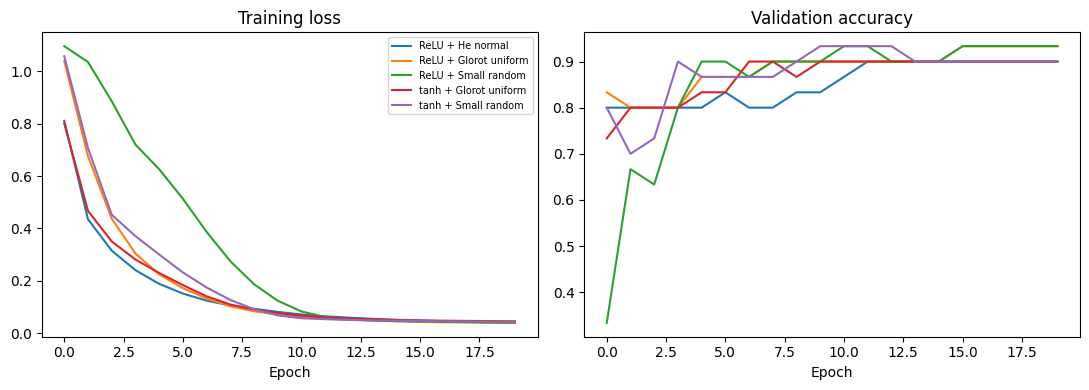

,Init,Loss epoch 1,Final val loss,Final val acc,Time (s)
0,ReLU + He normal,0.810251,0.293206,0.900000,3.951179
1,ReLU + Glorot uniform,1.038034,0.229489,0.933333,3.601439
2,ReLU + Small random,1.094933,0.195670,0.933333,3.659902
3,tanh + Glorot uniform,0.800958,0.249715,0.900000,3.887663
4,tanh + Small random,1.056598,0.233803,0.900000,4.316649


In [4]:
configs = [
    ('ReLU + He normal', 'relu', 'he_normal'),
    ('ReLU + Glorot uniform', 'relu', 'glorot_uniform'),
    ('ReLU + Small random', 'relu', keras.initializers.RandomNormal(stddev=0.01)),
    ('tanh + Glorot uniform', 'tanh', 'glorot_uniform'),
    ('tanh + Small random', 'tanh', keras.initializers.RandomNormal(stddev=0.01)),
]

rows = []
plt.figure(figsize=(11, 4))
for name, act, ini in configs:
    tf.random.set_seed(42)
    m = build_model(act=act, init=ini)
    h, t = train(m, 20, 16)
    rows.append([name, h.history['loss'][0], h.history['val_loss'][-1], h.history['val_accuracy'][-1], t])
    plt.subplot(1, 2, 1)
    plt.plot(h.history['loss'], label=name)
    plt.subplot(1, 2, 2)
    plt.plot(h.history['val_accuracy'], label=name)

plt.subplot(1, 2, 1)
plt.title('Training loss')
plt.xlabel('Epoch')
plt.legend(fontsize=7)
plt.subplot(1, 2, 2)
plt.title('Validation accuracy')
plt.xlabel('Epoch')
plt.tight_layout()
plt.show()

pd.DataFrame(rows, columns=['Init', 'Loss epoch 1', 'Final val loss', 'Final val acc', 'Time (s)'])

### 3. Learning rate strategies

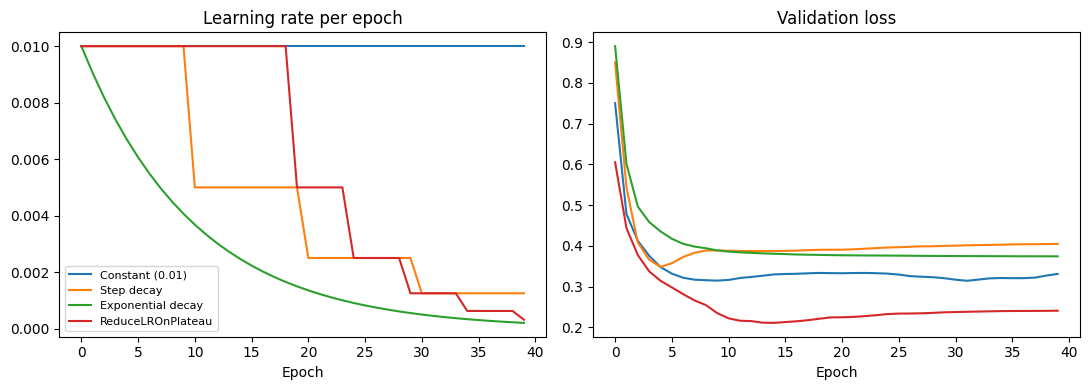

,Strategy,Best val loss,Final val acc,Final LR
0,Constant (0.01),0.314106,0.933333,0.010000
1,Step decay,0.348321,0.900000,0.001250
2,Exponential decay,0.374163,0.900000,0.000202
3,ReduceLROnPlateau,0.210723,0.933333,0.000312


In [5]:
class LRLog(keras.callbacks.Callback):
    def __init__(self):
        super().__init__()
        self.lrs = []
    def on_epoch_end(self, epoch, logs=None):
        self.lrs.append(float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate)))

strategies = {
    'Constant (0.01)': lambda: [],
    'Step decay': lambda: [keras.callbacks.LearningRateScheduler(lambda e: 0.01 * (0.5 ** (e // 10)))],
    'Exponential decay': lambda: [keras.callbacks.LearningRateScheduler(lambda e: 0.01 * np.exp(-0.1 * e))],
    'ReduceLROnPlateau': lambda: [keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-4)],
}

lr_hist = {}
lr_vals = {}
rows = []
for name, cb in strategies.items():
    tf.random.set_seed(42)
    m = build_model()
    log = LRLog()
    h, t = train(m, 40, 16, callbacks=cb() + [log])
    lr_hist[name] = h.history
    lr_vals[name] = log.lrs
    rows.append([name, min(h.history['val_loss']), h.history['val_accuracy'][-1], log.lrs[-1]])

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
for name in lr_vals:
    plt.plot(lr_vals[name], label=name)
plt.title('Learning rate per epoch')
plt.xlabel('Epoch')
plt.legend(fontsize=8)
plt.subplot(1, 2, 2)
for name in lr_hist:
    plt.plot(lr_hist[name]['val_loss'], label=name)
plt.title('Validation loss')
plt.xlabel('Epoch')
plt.tight_layout()
plt.show()

pd.DataFrame(rows, columns=['Strategy', 'Best val loss', 'Final val acc', 'Final LR'])

### 4. Batch size and epoch limit

In [6]:
rows = []
for bs in [8, 32]:
    for ep in [5, 50]:
        tf.random.set_seed(42)
        m = build_model()
        h, t = train(m, ep, bs)
        rows.append([bs, ep, t, h.history['loss'][-1], h.history['val_loss'][-1], h.history['val_accuracy'][-1]])

pd.DataFrame(rows, columns=['Batch size', 'Epochs', 'Time (s)', 'Train loss', 'Val loss', 'Val acc'])

,Batch size,Epochs,Time (s),Train loss,Val loss,Val acc
0,8,5,1.575699,0.196990,0.398365,0.800000
1,8,50,8.351015,0.002504,0.505719,0.900000
2,32,5,1.872178,0.506970,0.463735,0.833333
3,32,50,8.191783,0.030279,0.323639,0.900000


### 5. Overfitting controls

In [7]:
configs = {
    'Baseline': dict(),
    'L2 (0.01)': dict(l2=0.01),
    'L1 (0.001)': dict(l1=0.001),
    'Dropout (0.3)': dict(drop=0.3),
    'L2 + Dropout + EarlyStop': dict(l2=0.01, drop=0.2),
}

results = {}
rows = []
for name, kw in configs.items():
    tf.random.set_seed(42)
    m = build_model(units=64, lr=0.005, **kw)
    cb = []
    if 'EarlyStop' in name:
        cb = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)]
    h, t = train(m, 150, 16, callbacks=cb)
    results[name] = h.history
    test_loss, test_acc = m.evaluate(X_test, y_test, verbose=0)
    rows.append([name, len(h.history['loss']), h.history['loss'][-1], h.history['val_loss'][-1], min(h.history['val_loss']), test_acc])

pd.DataFrame(rows, columns=['Model', 'Epochs run', 'Last train loss', 'Last val loss', 'Best val loss', 'Test acc'])

,Model,Epochs run,Last train loss,Last val loss,Best val loss,Test acc
0,Baseline,150,0.000386,0.866719,0.501816,0.933333
1,L2 (0.01),150,0.091205,0.180487,0.180041,0.933333
2,L1 (0.001),150,0.084166,0.310614,0.296504,0.933333
3,Dropout (0.3),150,0.015400,0.514432,0.379509,0.900000
4,L2 + Dropout + EarlyStop,95,0.135019,0.230982,0.225609,0.966667


### 6. Learning curves

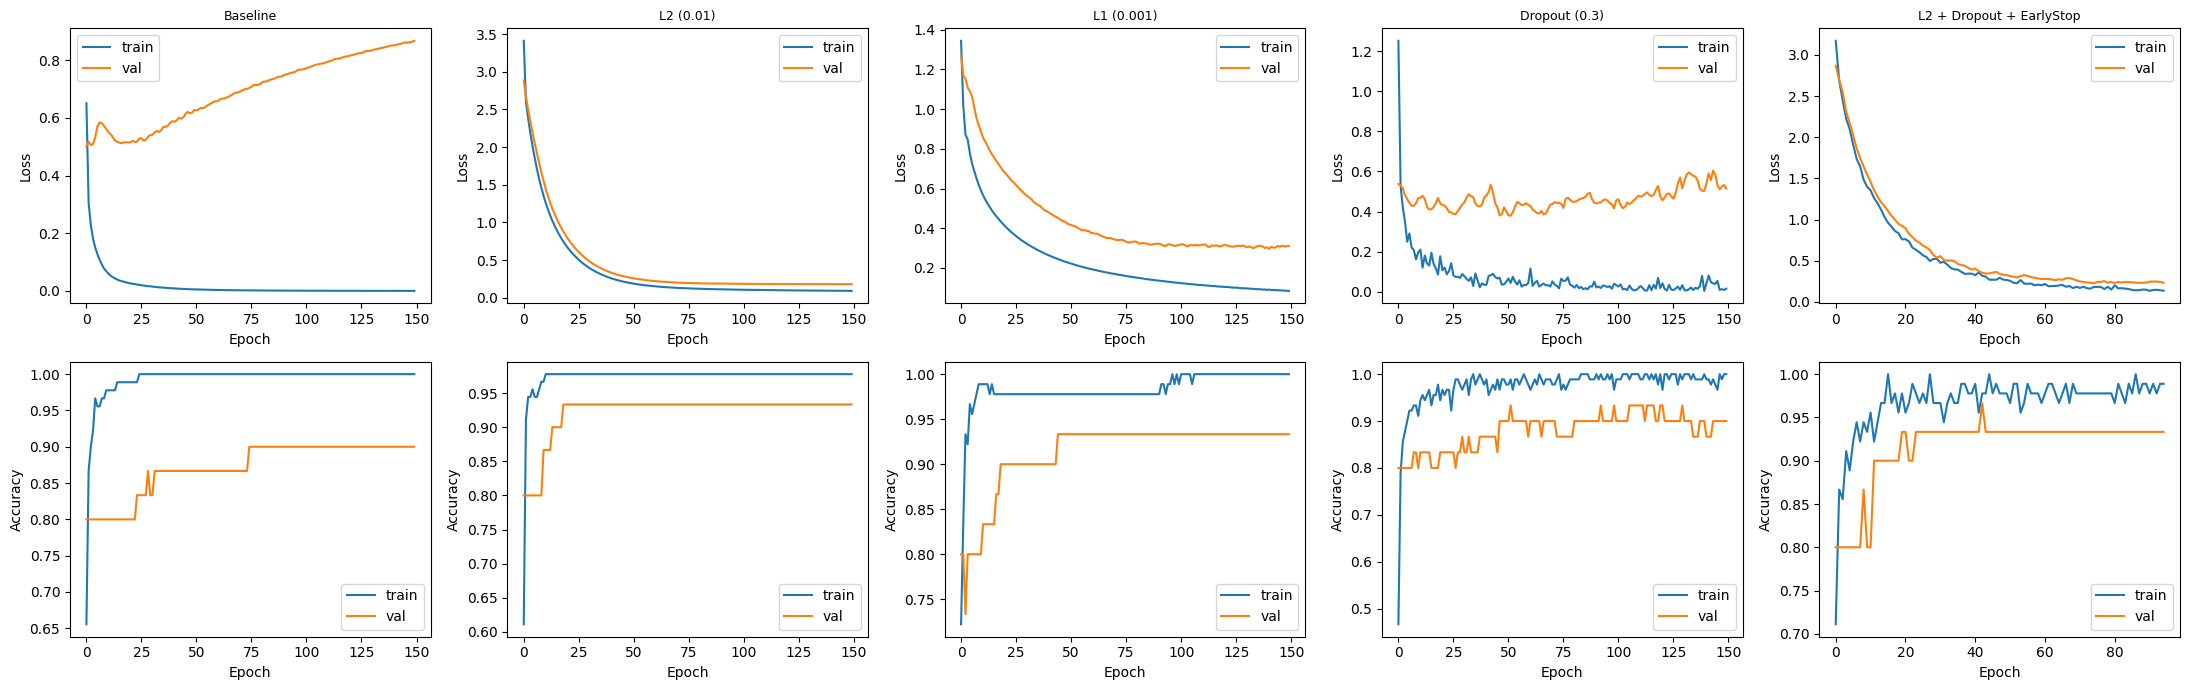

In [8]:
fig, ax = plt.subplots(2, 5, figsize=(22, 7))
for i, name in enumerate(results):
    h = results[name]
    ax[0, i].plot(h['loss'], label='train')
    ax[0, i].plot(h['val_loss'], label='val')
    ax[0, i].set_title(name, fontsize=9)
    ax[0, i].set_xlabel('Epoch')
    ax[0, i].set_ylabel('Loss')
    ax[0, i].legend()
    ax[1, i].plot(h['accuracy'], label='train')
    ax[1, i].plot(h['val_accuracy'], label='val')
    ax[1, i].set_xlabel('Epoch')
    ax[1, i].set_ylabel('Accuracy')
    ax[1, i].legend()
plt.tight_layout()
plt.show()

### Observations
**Initialization:** He (ReLU) and Glorot (tanh) start with the right variance, so their loss in the first epochs is lower than the tiny random initialization. After 20 epochs all of them reach almost the same validation accuracy, because Iris is a very small problem and Adam adapts the step sizes.

**Learning rate:** The constant rate works well here. Step and exponential decay lower the rate quickly, so in the later epochs learning becomes slow. ReduceLROnPlateau only lowers it when the validation loss stops improving, so it is the safer schedule. The learning rate per epoch is plotted above.

**Batch size and epochs:** With 5 epochs the model is underfitted (training loss is still high, more so for batch size 32 because it makes fewer updates per epoch). Batch size 8 learns faster per epoch but takes more time because there are more weight updates. With 50 epochs the training loss becomes very small and for batch size 8 the validation loss is higher than the training loss, which is the start of overfitting.

**Overfitting controls:** The baseline reaches a training loss close to 0 while its validation loss goes up after the best epoch, so it is overfitting. L2, L1 and dropout reduce the gap between training and validation loss, L2 gave the smallest validation loss. L2 + dropout with early stopping stopped before 150 epochs and restored the best weights, which gives a reasonable fit with similar test accuracy.

**Conclusion from curves:** 5 epochs = underfitting, baseline with 150 epochs = overfitting (train loss goes down, val loss goes up), regularized model with early stopping = reasonable fit (train and val curves are close). Only 30 validation and 30 test samples are used so small differences in accuracy are not very reliable.

# Task 2 - Adaline and Madaline

### Part A: Adaline

Net input = w.x + b, prediction = sign(net). Weights are updated with the delta (LMS) rule after every sample: w = w + lr * (t - net) * x. The loss used is the mean squared error between the target and the net input.

In [9]:
X_and = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]])
t_and = np.array([-1, -1, -1, 1])

class Adaline:
    def __init__(self, lr=0.05, epochs=50, seed=1):
        self.lr = lr
        self.epochs = epochs
        self.seed = seed

    def fit(self, X, t):
        rng = np.random.RandomState(self.seed)
        self.w = rng.uniform(-0.5, 0.5, X.shape[1])
        self.b = rng.uniform(-0.5, 0.5)
        self.mse = []
        for ep in range(self.epochs):
            for xi, ti in zip(X, t):
                net = np.dot(xi, self.w) + self.b
                err = ti - net
                self.w = self.w + self.lr * err * xi
                self.b = self.b + self.lr * err
            nets = X.dot(self.w) + self.b
            self.mse.append(np.mean((t - nets) ** 2))
        return self

    def predict(self, X):
        return np.where(X.dot(self.w) + self.b >= 0, 1, -1)

In [10]:
ada = Adaline(lr=0.05, epochs=50).fit(X_and, t_and)
print("weights:", ada.w)
print("bias:", ada.b)
print("final MSE:", ada.mse[-1])
print()
print("x1  x2  target  net     pred")
for xi, ti in zip(X_and, t_and):
    net = np.dot(xi, ada.w) + ada.b
    print(f"{xi[0]:2d}  {xi[1]:2d}  {ti:5d}  {net:6.3f}  {ada.predict(xi.reshape(1, -1))[0]:3d}")

weights: [0.51350179 0.52702093]
bias: -0.4999982114263706
final MSE: 0.2509124289248582

x1  x2  target  net     pred
-1  -1     -1  -1.541   -1
-1   1     -1  -0.486   -1
 1  -1     -1  -0.514   -1
 1   1      1   0.541    1


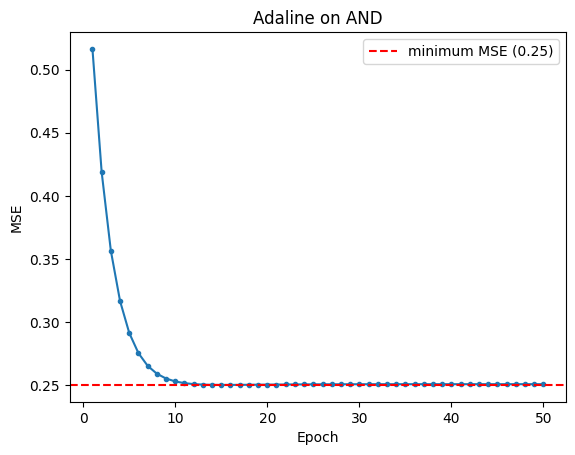

In [11]:
plt.plot(range(1, 51), ada.mse, marker='o', markersize=3)
plt.axhline(0.25, color='r', linestyle='--', label='minimum MSE (0.25)')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Adaline on AND')
plt.legend()
plt.show()

The MSE falls quickly and flattens at 0.25. This is the least squares minimum for AND because a linear net output cannot be exactly -1, -1, -1, +1 for all four inputs at the same time. The learning therefore converges (in roughly 20 to 30 epochs) and since the sign of the net input matches every target, all 4 predictions are correct.

### Part B: Madaline

**Architecture:** 2 inputs -> 2 hidden Adaline units (sign activation) -> 1 output unit with bipolar output.
The output unit has fixed weights (1, 1) and bias -1, so it works as an AND of the two hidden outputs.

**Learning rule (MRI):** for every sample the output is checked. If it is wrong, the hidden unit whose net input is closest to zero is flipped first. If the flip gives the correct output, that unit is updated with the LMS rule towards the flipped value. Otherwise the next closest unit is tried. Training stops when an epoch has no errors.

In [12]:
X_xor = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]])
t_xor = np.array([-1, 1, 1, -1])

def sign(z):
    return np.where(z >= 0, 1, -1)

class Madaline:
    def __init__(self, lr=0.1, epochs=200, seed=0):
        self.lr = lr
        self.epochs = epochs
        self.seed = seed
        self.v = np.array([1, 1])
        self.vb = -1

    def output(self, h):
        return 1 if np.dot(self.v, h) + self.vb >= 0 else -1

    def fit(self, X, t):
        rng = np.random.RandomState(self.seed)
        self.W = rng.uniform(-0.5, 0.5, (2, X.shape[1]))
        self.b = rng.uniform(-0.5, 0.5, 2)
        self.errors = []
        for ep in range(self.epochs):
            err_count = 0
            for xi, ti in zip(X, t):
                z = self.W.dot(xi) + self.b
                h = sign(z)
                if self.output(h) != ti:
                    err_count += 1
                    for j in np.argsort(np.abs(z)):
                        h_new = h.copy()
                        h_new[j] = -h[j]
                        if self.output(h_new) == ti:
                            self.W[j] = self.W[j] + self.lr * (h_new[j] - z[j]) * xi
                            self.b[j] = self.b[j] + self.lr * (h_new[j] - z[j])
                            break
            self.errors.append(err_count)
            if err_count == 0:
                break
        return self

    def predict(self, X):
        out = []
        for xi in X:
            h = sign(self.W.dot(xi) + self.b)
            out.append(self.output(h))
        return np.array(out)

converged with seed 3 in 2 epochs
hidden weights:
[[ 0.16419803  0.32154795]
 [-0.3288978  -0.10897494]]
hidden bias: [0.27954683 0.27649055]

x1  x2  target  pred
-1  -1     -1    -1
-1   1      1     1
 1  -1      1     1
 1   1     -1    -1


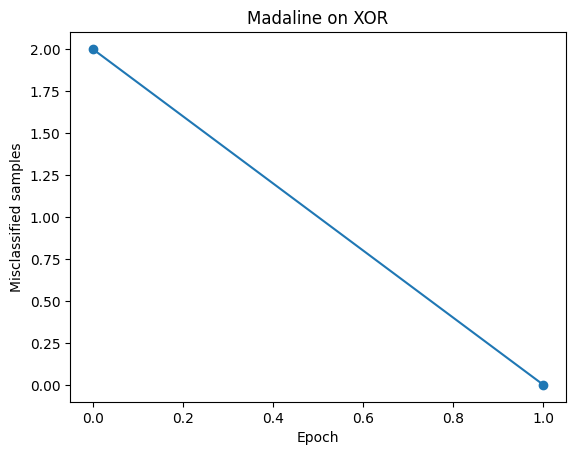

In [13]:
mad = None
for s in range(20):
    m = Madaline(lr=0.1, epochs=200, seed=s).fit(X_xor, t_xor)
    if m.errors[-1] == 0:
        mad = m
        print("converged with seed", s, "in", len(m.errors), "epochs")
        break

print("hidden weights:")
print(mad.W)
print("hidden bias:", mad.b)
print()
print("x1  x2  target  pred")
for xi, ti, pi in zip(X_xor, t_xor, mad.predict(X_xor)):
    print(f"{xi[0]:2d}  {xi[1]:2d}  {ti:5d}  {pi:4d}")

plt.plot(mad.errors, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Misclassified samples')
plt.title('Madaline on XOR')
plt.show()

In [14]:
ada_xor = Adaline(lr=0.05, epochs=100).fit(X_xor, t_xor)
print("single Adaline on XOR")
print("weights:", ada_xor.w, "bias:", ada_xor.b)
print("final MSE:", ada_xor.mse[-1])
print("predictions:", ada_xor.predict(X_xor), "targets:", t_xor)

single Adaline on XOR
weights: [-0.02702703 -0.05405405] bias: -2.1700251318090835e-10
final MSE: 1.0036523009524794
predictions: [ 1 -1  1 -1] targets: [-1  1  1 -1]


A single Adaline makes a decision with one straight line (w1*x1 + w2*x2 + b = 0). In XOR the two +1 points and the two -1 points sit on opposite corners, so no single line can separate them. The LMS weights go to about zero and the MSE stays near 1, so the Adaline gets only about half of the points right.

In the Madaline each hidden unit draws its own line (one acts like OR, the other like NAND) and the output unit combines them with AND. The region between the two lines is the +1 class, so the network can make a nonlinear decision boundary and solve XOR.

# Task 3 - Pattern Association and Associative Memory

In [15]:
def sgn(z):
    return np.where(z >= 0, 1, -1)

def show(v):
    return ''.join('+' if i > 0 else '-' for i in v)

### 13. Heteroassociative memory
Weight matrix by Hebb rule: W = sum of outer(x_k, y_k). Recall: y = sign(x . W).

In [16]:
x_hetero = np.array([
    [1, -1, 1, -1, 1, -1, 1, -1],
    [1, 1, -1, -1, 1, 1, -1, -1],
    [1, 1, 1, 1, -1, -1, -1, -1],
])
y_hetero = np.array([
    [1, 1, -1, -1],
    [1, -1, 1, -1],
    [-1, 1, 1, -1],
])

W_het = np.zeros((8, 4))
for x, y in zip(x_hetero, y_hetero):
    W_het = W_het + np.outer(x, y)
print(W_het)
print()

for x, y in zip(x_hetero, y_hetero):
    rec = sgn(x.dot(W_het))
    print(show(x), "->", show(rec), "target", show(y), "match:", np.array_equal(rec, y))

[[ 1.  1.  1. -3.]
 [-1. -1.  3. -1.]
 [-1.  3. -1. -1.]
 [-3.  1.  1.  1.]
 [ 3. -1. -1. -1.]
 [ 1. -3.  1.  1.]
 [ 1.  1. -3.  1.]
 [-1. -1. -1.  3.]]

+-+-+-+- -> ++-- target ++-- match: True
++--++-- -> +-+- target +-+- match: True
++++---- -> -++- target -++- match: True


### 14. Autoassociative memory
Weight matrix: W = sum of outer(p_k, p_k). Recall: p = sign(W . x).

In [17]:
from scipy.linalg import hadamard

patterns = hadamard(16)[[3, 5, 6]]

W_auto = np.zeros((16, 16))
for p in patterns:
    W_auto = W_auto + np.outer(p, p)

rng = np.random.RandomState(3)
rows = []
for i, p in enumerate(patterns):
    for k in [0, 1, 2, 3, 5]:
        q = p.copy()
        idx = rng.choice(16, k, replace=False)
        q[idx] = -q[idx]
        rec = sgn(W_auto.dot(q))
        rows.append(['P' + str(i + 1) + ' ' + show(p), str(k) + ' bit(s) flipped: ' + show(q), show(rec), np.array_equal(rec, p)])

table = pd.DataFrame(rows, columns=['Stored pattern', 'Query / noise', 'Recalled output', 'Exact match'])
table

,Stored pattern,Query / noise,Recalled output,Exact match
0,P1 +--++--++--++--+,0 bit(s) flipped: +--++--++--++--+,+--++--++--++--+,True
1,P1 +--++--++--++--+,1 bit(s) flipped: +--++--++---+--+,+--++--++--++--+,True
2,P1 +--++--++--++--+,2 bit(s) flipped: +-+++--++--+++-+,+--++--++--++--+,True
3,P1 +--++--++--++--+,3 bit(s) flipped: +--++--+++++---+,+--++--++--++--+,True
4,P1 +--++--++--++--+,5 bit(s) flipped: ---+--+++-+++---,+--++--++--++--+,True
5,P2 +-+--+-++-+--+-+,0 bit(s) flipped: +-+--+-++-+--+-+,+-+--+-++-+--+-+,True
6,P2 +-+--+-++-+--+-+,1 bit(s) flipped: +-+--+-++-+--+++,+-+--+-++-+--+-+,True
7,P2 +-+--+-++-+--+-+,2 bit(s) flipped: +-+----++----+-+,+-+--+-++-+--+-+,True
8,P2 +-+--+-++-+--+-+,3 bit(s) flipped: +-+--++++++--+++,+++--++++++--+++,False
9,P2 +-+--+-++-+--+-+,5 bit(s) flipped: --+----+--+-+--+,+-+--+-++-+--+-+,True


### 15. Discussion
The heteroassociative memory recalls all 3 stored pairs exactly. The autoassociative memory recalls every clean pattern and most noisy ones, but it fails for some noisy queries (see the False row in the table). The recall is done in one step, so when the flipped bits make the query closer to another stored pattern the output goes to the wrong pattern, and the success depends on which bits are flipped. Other limitations are that only a few patterns can be stored (the patterns here are orthogonal, correlated patterns would give crosstalk) and that there is no repeated update to clean the noise, which the Hopfield network in Task 4 does.

# Task 4 - Hopfield Network

In [18]:
from scipy.linalg import hadamard

H = hadamard(16)
pats = H[[3, 5, 6]]
N = pats.shape[1]

W = np.zeros((N, N))
for p in pats:
    W = W + np.outer(p, p)
np.fill_diagonal(W, 0)

print("patterns:")
for p in pats:
    print(show(p))
print()
print("weight matrix:")
print(W.astype(int))

patterns:
+--++--++--++--+
+-+--+-++-+--+-+
++----++++----++

weight matrix:
[[ 0 -1 -1 -1 -1 -1 -1  3  3 -1 -1 -1 -1 -1 -1  3]
 [-1  0 -1 -1 -1 -1  3 -1 -1  3 -1 -1 -1 -1  3 -1]
 [-1 -1  0 -1 -1  3 -1 -1 -1 -1  3 -1 -1  3 -1 -1]
 [-1 -1 -1  0  3 -1 -1 -1 -1 -1 -1  3  3 -1 -1 -1]
 [-1 -1 -1  3  0 -1 -1 -1 -1 -1 -1  3  3 -1 -1 -1]
 [-1 -1  3 -1 -1  0 -1 -1 -1 -1  3 -1 -1  3 -1 -1]
 [-1  3 -1 -1 -1 -1  0 -1 -1  3 -1 -1 -1 -1  3 -1]
 [ 3 -1 -1 -1 -1 -1 -1  0  3 -1 -1 -1 -1 -1 -1  3]
 [ 3 -1 -1 -1 -1 -1 -1  3  0 -1 -1 -1 -1 -1 -1  3]
 [-1  3 -1 -1 -1 -1  3 -1 -1  0 -1 -1 -1 -1  3 -1]
 [-1 -1  3 -1 -1  3 -1 -1 -1 -1  0 -1 -1  3 -1 -1]
 [-1 -1 -1  3  3 -1 -1 -1 -1 -1 -1  0  3 -1 -1 -1]
 [-1 -1 -1  3  3 -1 -1 -1 -1 -1 -1  3  0 -1 -1 -1]
 [-1 -1  3 -1 -1  3 -1 -1 -1 -1  3 -1 -1  0 -1 -1]
 [-1  3 -1 -1 -1 -1  3 -1 -1  3 -1 -1 -1 -1  0 -1]
 [ 3 -1 -1 -1 -1 -1 -1  3  3 -1 -1 -1 -1 -1 -1  0]]


### 17. Asynchronous recall
One neuron is updated at a time in random order using s_i = sign(sum_j w_ij s_j). If the net input is exactly 0 (tie), the neuron keeps its previous state. Recall stops when a full sweep makes no change or when the maximum number of sweeps is reached.

In [19]:
def energy(W, s):
    return -0.5 * s.dot(W).dot(s)

def recall(W, s, max_sweeps=20, track=False):
    s = s.copy()
    log = [(0, None, None, None, energy(W, s))]
    steps = 0
    for sweep in range(max_sweeps):
        changed = False
        for i in np.random.permutation(len(s)):
            net = W[i].dot(s)
            old = s[i]
            if net > 0:
                s[i] = 1
            elif net < 0:
                s[i] = -1
            steps += 1
            if s[i] != old:
                changed = True
            log.append((steps, i, old, s[i], energy(W, s)))
        if not changed:
            break
    if track:
        return s, log
    return s

for p in pats:
    print(show(p), "stable:", np.array_equal(recall(W, p), p))

+--++--++--++--+ stable: True
+-+--+-++-+--+-+ stable: True
++----++++----++ stable: True


### 18. Recall with corrupted patterns

 Flipped bits  Pattern 1 (%)  Pattern 2 (%)  Pattern 3 (%)  Average (%)
            0          100.0          100.0          100.0   100.000000
            1          100.0          100.0          100.0   100.000000
            2          100.0          100.0          100.0   100.000000
            3           89.0           93.0           91.0    91.000000
            4           80.0           83.0           80.0    81.000000
            5           55.0           51.0           52.0    52.666667
            6           33.0           25.0           41.0    33.000000
            8            4.0            1.0            2.0     2.333333


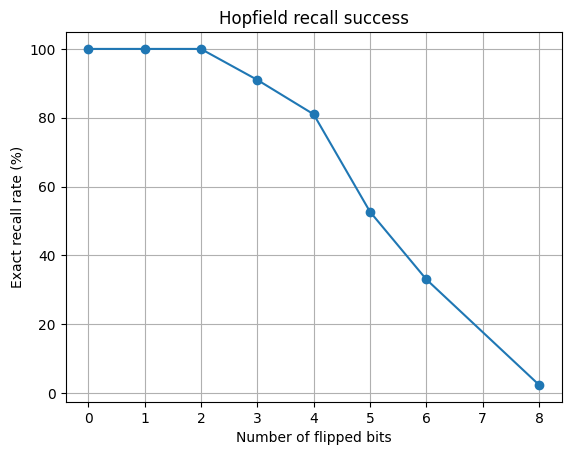

In [20]:
np.random.seed(0)
trials = 100
flip_list = [0, 1, 2, 3, 4, 5, 6, 8]
rows = []
for k in flip_list:
    row = [k]
    for p in pats:
        ok = 0
        for t in range(trials):
            q = p.copy()
            idx = np.random.choice(N, k, replace=False)
            q[idx] = -q[idx]
            if np.array_equal(recall(W, q), p):
                ok += 1
        row.append(ok / trials * 100)
    row.append(np.mean(row[1:]))
    rows.append(row)

res = pd.DataFrame(rows, columns=['Flipped bits', 'Pattern 1 (%)', 'Pattern 2 (%)', 'Pattern 3 (%)', 'Average (%)'])
print(res.to_string(index=False))

plt.plot(res['Flipped bits'], res['Average (%)'], marker='o')
plt.xlabel('Number of flipped bits')
plt.ylabel('Exact recall rate (%)')
plt.title('Hopfield recall success')
plt.grid(True)
plt.show()

### 19. Energy during asynchronous updates

original : +--++--++--++--+
corrupted: ++-+++--+--++--+
recalled : +--++--++--++--+

 Step  Neuron  Old state  New state  Energy
    0     NaN        NaN        NaN   -30.0
   13     7.0       -1.0        1.0   -48.0
   14     5.0        1.0       -1.0   -78.0
   15     1.0        1.0       -1.0  -104.0


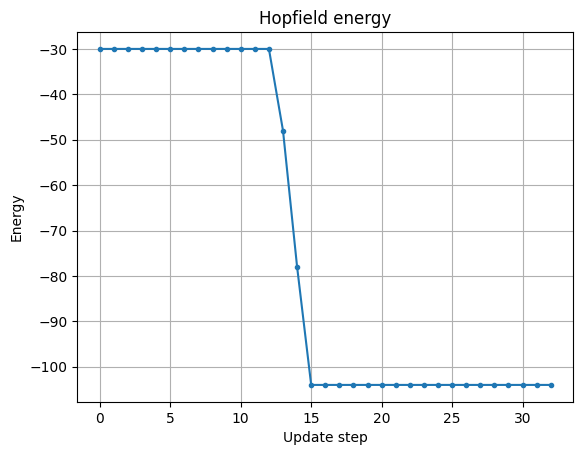

In [21]:
np.random.seed(5)
q = pats[0].copy()
idx = np.random.choice(N, 3, replace=False)
q[idx] = -q[idx]
print("original :", show(pats[0]))
print("corrupted:", show(q))

out, log = recall(W, q, track=True)
print("recalled :", show(out))
print()

steps = pd.DataFrame(log, columns=['Step', 'Neuron', 'Old state', 'New state', 'Energy'])
print(steps[steps['Old state'] != steps['New state']].to_string(index=False))

plt.plot(steps['Step'], steps['Energy'], marker='o', markersize=3)
plt.xlabel('Update step')
plt.ylabel('Energy')
plt.title('Hopfield energy')
plt.grid(True)
plt.show()

### Observations
The stored patterns are stable states (recall of a clean pattern returns the same pattern). The recall rate is 100% for 1 and 2 flipped bits and then falls as more bits are flipped. At 8 flipped bits (half of the neurons) the query is as far from the stored pattern as it can be and the network almost never recovers it. This is expected because the inverse of a stored pattern is also a stable state and some states can be spurious minima.

**Energy:** E = -1/2 sum w_ij s_i s_j. Each asynchronous update flips a neuron only if that lowers the energy (or keeps it the same), and since W is symmetric with zero diagonal the energy can never increase. So the network moves downhill from the corrupted pattern until it reaches a local minimum, which is the stored pattern. In the table above, the energy only changes at the neurons that were flipped back and ends at the lowest value.